In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv('data_science_job (1).csv')
df

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19153,7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14.0,NaN,NaN,42.0,1.0
19154,31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14.0,NaN,NaN,52.0,1.0
19155,24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,50-99,Pvt Ltd,44.0,0.0
19156,5756,city_65,0.802,Male,Has relevent experience,no_enrollment,High School,NaN,0.0,500-999,Pvt Ltd,97.0,0.0


In [5]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [6]:
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [7]:
df.shape

(19158, 13)

In [13]:
cols=[var for var in df.columns if df[var].isnull().mean() <0.05 and df[var].isnull().mean()>0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [15]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
15377,0.743,Part time course,Graduate,4.0,334.0
11522,0.920,no_enrollment,Graduate,20.0,20.0
14839,0.843,Full time course,Graduate,9.0,NaN
6395,0.903,no_enrollment,Phd,20.0,54.0
11063,0.920,no_enrollment,Graduate,20.0,22.0


In [25]:
df['enrolled_university'].value_counts()

enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
Name: count, dtype: int64

In [26]:
df['education_level'].value_counts()

education_level
Graduate          11598
Masters            4361
High School        2017
Phd                 414
Primary School      308
Name: count, dtype: int64

In [16]:
len(df[cols].dropna())/len(df)

0.8968577095730244

In [17]:
new_df=df[cols].dropna()
df.shape,new_df.shape

((19158, 13), (17182, 5))

In [27]:
temp=pd.concat([
    #percentage of the observation per category:  original data
    df['education_level'].value_counts()/len(df),

    #percentage of the observation per category: cca dataset
    new_df['education_level'].value_counts()/len(df)
],axis=1)
# add column names:
temp.columns=['original','cca']
temp

,original,cca
education_level,,
Graduate,0.605387,0.555904
Masters,0.227633,0.209938
High School,0.105282,0.096304
Phd,0.021610,0.019835
Primary School,0.016077,0.014876


In [29]:
temp=pd.concat([
    #percentage of observation per category, original dataset
    df['city_development_index'].value_counts()/len(df),

    #percentage of observations per category, cca dataset
    new_df['city_development_index'].value_counts()/len(df)
               ],axis=1)
# add column names:
temp.columns=['original','cca']
temp

,original,cca
city_development_index,,
0.920,0.265059,0.249087
0.624,0.136705,0.123552
0.910,0.078401,0.072972
0.926,0.067700,0.062063
0.698,0.034659,0.029648
...,...,...
0.649,0.000209,0.000157
0.807,0.000209,0.000209
0.781,0.000157,0.000157


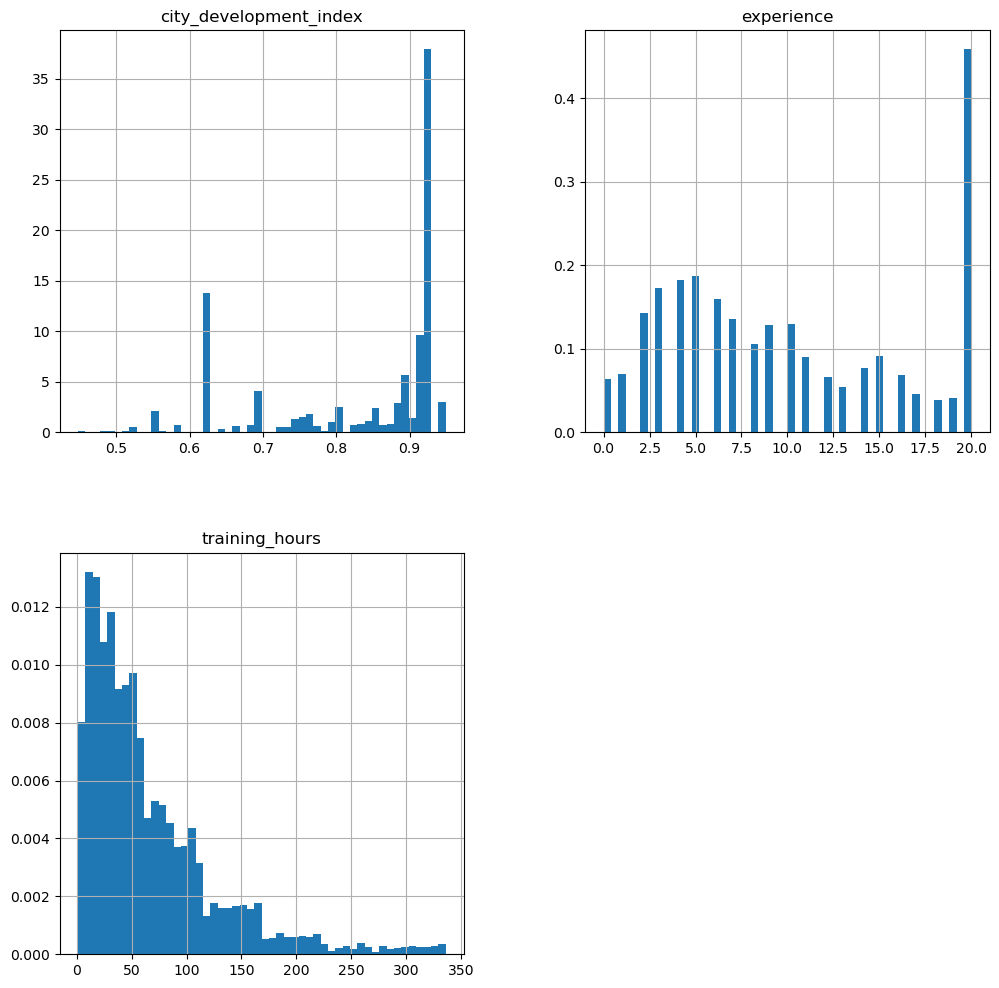

In [18]:
new_df.hist(bins=50,density=True,figsize=(12,12))
plt.show()

<Axes: >

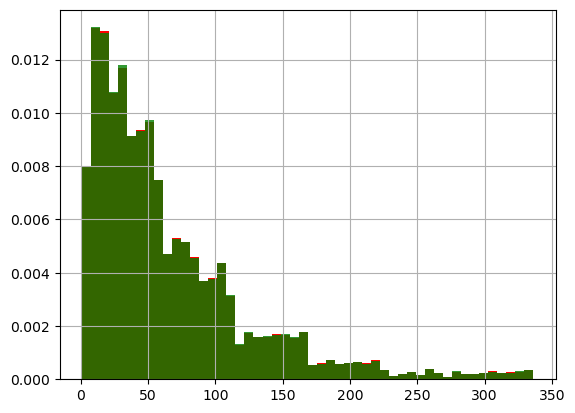

In [19]:
fig=plt.figure()
ax=fig.add_subplot(111)
#Original data:
df['training_hours'].hist(bins=50,ax=ax,density=True,color='red')
#Data after cca the argument alpha makes the color transparent so we can see the over lay of the 2 distributions
new_df['training_hours'].hist(bins=50,ax=ax,density=True,color='green',alpha=0.8)

<Axes: >

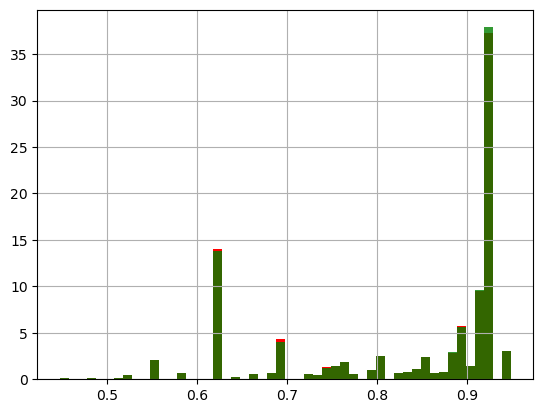

In [21]:
fig=plt.figure()
ax=fig.add_subplot(111)
#Orginal data:
df['city_development_index'].hist(bins=50,ax=ax,density=True,color='red')
#Data after cca,the argument alpha makes the color transparent , so we can see the overlap of the 2 distributions :
new_df['city_development_index'].hist(bins=50,ax=ax,color='green',density=True,alpha=0.8)


<Axes: ylabel='Density'>

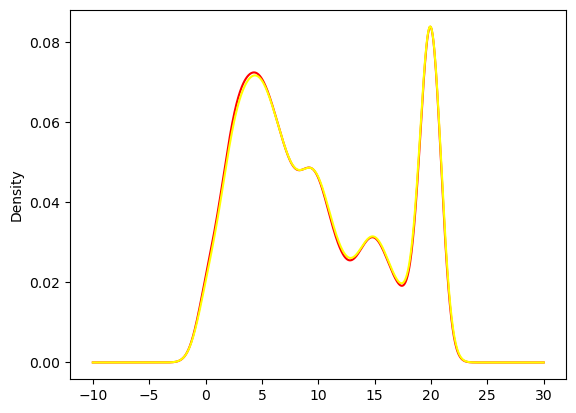

In [24]:
fig=plt.figure()
ax=fig.add_subplot(111)
#Original Data
df['experience'].plot.density(color='red')
#Data after cca
new_df['experience'].plot.density(color='yellow')
